In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
left_image = plt.imread('left.png')
left_image=(left_image * 255).astype(np.uint8)
right_image = plt.imread('right.png')
right_image = (right_image * 255).astype(np.uint8)

In [16]:
def normalized_histogram(image):
    image_flat = image.flatten()
    hist = np.bincount(image_flat, minlength=256)
    total_pixels = np.sum(hist)
    if total_pixels > 0:
        hist = hist / total_pixels
    else:
        hist = np.zeros_like(hist)
    return hist

def compute_joint_histogram(image1, image2, bins=256):
    """Compute joint histogram from two images without using np.histogram2d."""
    joint_hist = np.zeros((bins, bins))
    for i in range(image1.shape[0]):
        for j in range(image1.shape[1]):
            joint_hist[image1[i, j], image2[i, j]] += 1
    joint_hist /= np.sum(joint_hist)  # Normalize
    return joint_hist
def check_joint_histogram(p_xy, r_x, s_y):
    """
    Check if the given joint histogram p_xy belongs to \Pi(r, s)
    by verifying if its marginals match r_x and s_y.
    """
    computed_r_x = np.sum(p_xy, axis=1)  # Sum over columns to get r_X
    computed_s_y = np.sum(p_xy, axis=0)  # Sum over rows to get s_Y
    return np.allclose(computed_r_x, r_x) and np.allclose(computed_s_y, s_y)

def kl_divergence(p, q):
    p, q = np.array(p), np.array(q)
    with np.errstate(divide='ignore', invalid='ignore'):
        divergence = np.where(p != 0, p * np.log2(p / q), 0)
    return np.sum(divergence)
def js_divergence(p, q):
    m = 0.5 * (p + q)
    return 0.5 * (kl_divergence(p, m) + kl_divergence(q, m))

def wasserstein_distance(p_xy, r_x, s_y):
    """Compute the Wasserstein-1 distance using joint histogram and marginals."""
    left_cdf = np.cumsum(r_x)
    right_cdf = np.cumsum(s_y)
    return np.sum(np.abs(left_cdf - right_cdf))
hist_left = normalized_histogram(left_image)
hist_right = normalized_histogram(right_image)

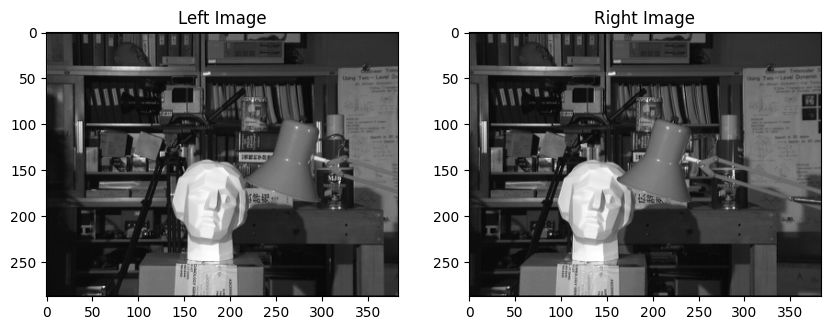

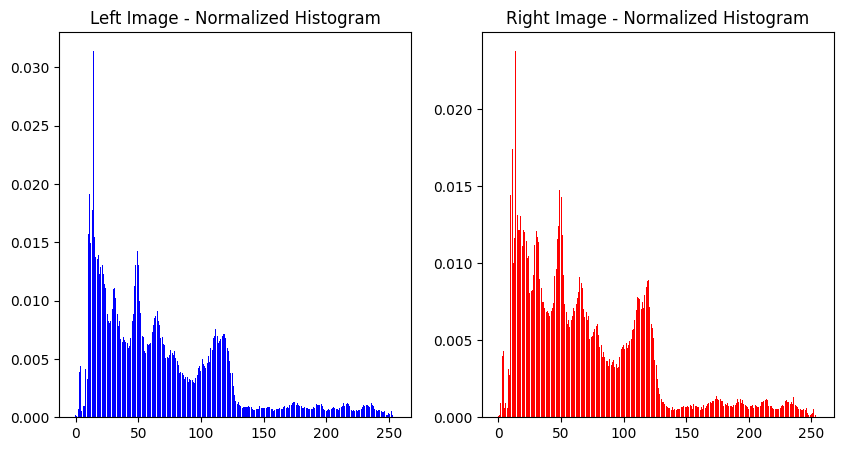

In [17]:
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.imshow(left_image, cmap='gray')
plt.title('Left Image')
plt.subplot(1, 2, 2)
plt.imshow(right_image, cmap='gray')
plt.title('Right Image')
plt.show()
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.bar(range(256), hist_left, color='blue')
plt.title('Left Image - Normalized Histogram')
plt.subplot(1, 2, 2)
plt.bar(range(256), hist_right, color='red')
plt.title('Right Image - Normalized Histogram')
plt.show()

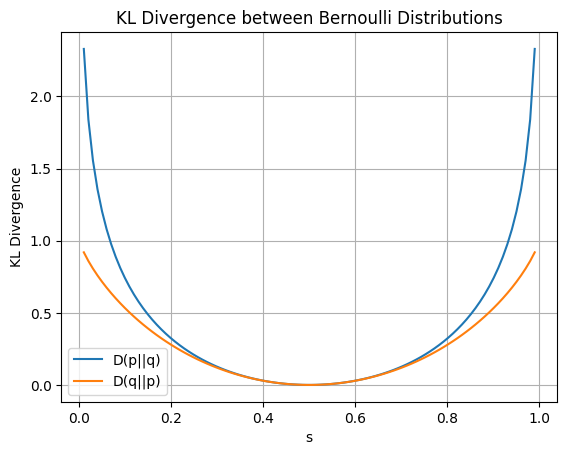

D(p||q) and D(q||p) are non-negative and not equal when r != s
Zero only when r = s.
D(left||right): 0.0151
D(right||left): 0.0144
---------------------------------------------
Observations:
The KL divergence values are small and similar, indicating that the intensity distributions of the two images are quite similar.
But in reality there is a difference between the two image was noticable and some what similar at middle but not at the edges.
It measures how one probability distribution diverges from another but does not account for the symmetry of the comparison, we can use MSE,SSIM and other metrics for better comparisons.


In [18]:
def plot_kl_divergence():
    r = 0.5
    s_values = np.linspace(0.01, 0.99, 100)
    D_pq = []
    D_qp = []

    for s in s_values:
        p = [r, 1 - r]
        q = [s, 1 - s]
        D_pq.append(kl_divergence(p, q))
        D_qp.append(kl_divergence(q, p))

    plt.plot(s_values, D_pq, label='D(p||q)')
    plt.plot(s_values, D_qp, label='D(q||p)')
    plt.title('KL Divergence between Bernoulli Distributions')
    plt.xlabel('s')
    plt.ylabel('KL Divergence')
    plt.legend()
    plt.grid(True)
    plt.show()
    print(f"D(p||q) and D(q||p) are non-negative and not equal when r != s")
    print(f"Zero only when r = s.")
plot_kl_divergence()
D_pq = kl_divergence(hist_left, hist_right)
D_qp = kl_divergence(hist_right, hist_left)
print(f"D(left||right): {D_pq:.4f}")
print(f"D(right||left): {D_qp:.4f}")
print("---------------------------------------------")
print("Observations:")
print("The KL divergence values are small and similar, indicating that the intensity distributions of the two images are quite similar.")
print("But in reality there is a difference between the two image was noticable and some what similar at middle but not at the edges.")
print("It measures how one probability distribution diverges from another but does not account for the symmetry of the comparison, we can use MSE,SSIM and other metrics for better comparisons.")

In [19]:
kl_pq = kl_divergence(hist_left, hist_right)
kl_qp = kl_divergence( hist_right,hist_left)
print(f"KL Divergence D(p||q): {kl_pq}")
print(f"KL Divergence D(q||p): {kl_qp}")
print(f"Is KL Divergence symmetric: {'True' if kl_pq == kl_qp else 'False'}")

KL Divergence D(p||q): 0.015104015237387055
KL Divergence D(q||p): 0.014409785833354477
Is KL Divergence symmetric: False


In [20]:
js_pq = js_divergence(hist_left, hist_right)
js_qp = js_divergence( hist_right,hist_left)
print(f"JS Divergence J(p,q): {js_pq}")
print(f"JS Divergence J(q,p): {js_qp}")
print(f"Is JS Divergence symmetric: {'True' if js_pq == js_qp else 'False'}")

JS Divergence J(p,q): 0.0036730397693148288
JS Divergence J(q,p): 0.0036730397693148288
Is JS Divergence symmetric: True


In [22]:
# Compute joint histogram from scratch
p_xy = compute_joint_histogram(left_image, right_image)
r_x = np.sum(p_xy, axis=1)
s_y = np.sum(p_xy, axis=0)

# Check if joint histogram belongs to \Pi(r, s)
print(f"Does p(X,Y) belong to \Pi(r, s)? {check_joint_histogram(p_xy, r_x, s_y)}")

# Compute Wasserstein distance
wasserstein_dist = wasserstein_distance(p_xy, r_x, s_y)
print(f"Wasserstein Distance: {wasserstein_dist}")

# Positive Example: Valid joint histogram
valid_p_xy = p_xy.copy()
print(f"Positive Example: {check_joint_histogram(valid_p_xy, r_x, s_y)}")  # Should be True

# Negative Example: Modify joint histogram to break marginal constraints
invalid_p_xy = p_xy.copy()
invalid_p_xy[0, 0] += 0.1  # Introduce an inconsistency
invalid_p_xy /= np.sum(invalid_p_xy)  # Renormalize
print(f"Negative Example: {check_joint_histogram(invalid_p_xy, r_x, s_y)}")  # Should be False"

Does p(X,Y) belong to \Pi(r, s)? True
Wasserstein Distance: 2.4144603587964086
Positive Example: True
Negative Example: False


# 2. GAN

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Hyperparameters
latent_dim = 100
batch_size = 128
lr = 0.0002
beta1 = 0.5
epochs = 25
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Generator class
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class Generator(nn.Module):
    def __init__(self, latent_dim):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, z):
        return self.model(z)

# Discriminator class
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )
    
    def forward(self, img):
        return self.model(img)

# Initialize models
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
generator.apply(weights_init)
discriminator.apply(weights_init)

# Optimizers and loss function
criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))

Epoch [0/25] Batch 0/469 	 D Loss: 1.4630 G Loss: 0.8090
Epoch [0/25] Batch 100/469 	 D Loss: 0.4593 G Loss: 2.2454
Epoch [0/25] Batch 200/469 	 D Loss: 0.3097 G Loss: 2.2856
Epoch [0/25] Batch 300/469 	 D Loss: 0.7052 G Loss: 5.9545
Epoch [0/25] Batch 400/469 	 D Loss: 0.1838 G Loss: 2.2482


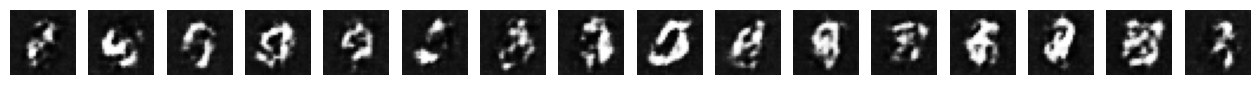

Epoch [1/25] Batch 0/469 	 D Loss: 0.2179 G Loss: 2.9938
Epoch [1/25] Batch 100/469 	 D Loss: 0.2531 G Loss: 1.9298
Epoch [1/25] Batch 200/469 	 D Loss: 0.3637 G Loss: 2.2556
Epoch [1/25] Batch 300/469 	 D Loss: 0.2519 G Loss: 2.4316
Epoch [1/25] Batch 400/469 	 D Loss: 0.2934 G Loss: 2.6850


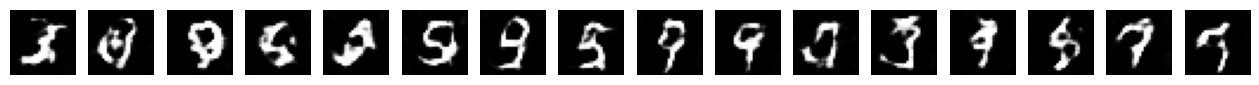

Epoch [2/25] Batch 0/469 	 D Loss: 0.4261 G Loss: 1.3076
Epoch [2/25] Batch 100/469 	 D Loss: 0.2790 G Loss: 2.2313
Epoch [2/25] Batch 200/469 	 D Loss: 0.4142 G Loss: 1.8845
Epoch [2/25] Batch 300/469 	 D Loss: 0.3671 G Loss: 2.1587
Epoch [2/25] Batch 400/469 	 D Loss: 0.5274 G Loss: 2.2173


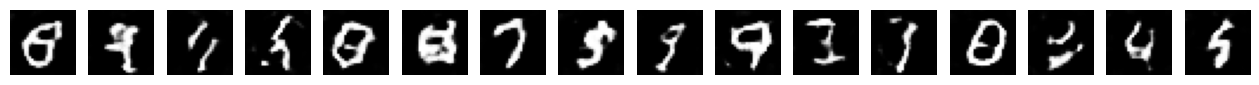

Epoch [3/25] Batch 0/469 	 D Loss: 0.6275 G Loss: 1.8111
Epoch [3/25] Batch 100/469 	 D Loss: 0.4338 G Loss: 2.3221
Epoch [3/25] Batch 200/469 	 D Loss: 2.7687 G Loss: 0.2614
Epoch [3/25] Batch 300/469 	 D Loss: 0.8011 G Loss: 1.3098
Epoch [3/25] Batch 400/469 	 D Loss: 0.5045 G Loss: 1.6332


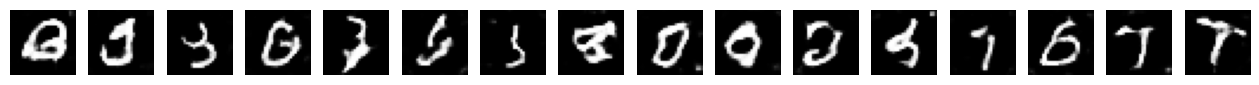

Epoch [4/25] Batch 0/469 	 D Loss: 1.1400 G Loss: 2.1597
Epoch [4/25] Batch 100/469 	 D Loss: 0.7666 G Loss: 0.9614
Epoch [4/25] Batch 200/469 	 D Loss: 0.5405 G Loss: 1.7283
Epoch [4/25] Batch 300/469 	 D Loss: 0.6366 G Loss: 1.4774
Epoch [4/25] Batch 400/469 	 D Loss: 0.5296 G Loss: 2.0264


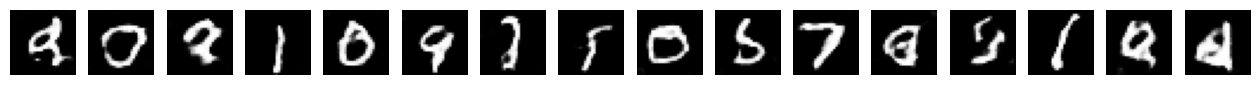

Epoch [5/25] Batch 0/469 	 D Loss: 0.7349 G Loss: 2.0900
Epoch [5/25] Batch 100/469 	 D Loss: 0.5076 G Loss: 2.0253
Epoch [5/25] Batch 200/469 	 D Loss: 0.5856 G Loss: 1.3711
Epoch [5/25] Batch 300/469 	 D Loss: 0.8680 G Loss: 1.4388
Epoch [5/25] Batch 400/469 	 D Loss: 0.5673 G Loss: 1.6761


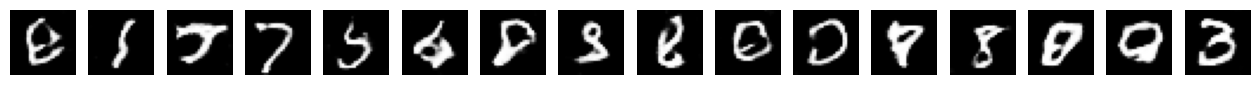

Epoch [6/25] Batch 0/469 	 D Loss: 0.7703 G Loss: 1.2766
Epoch [6/25] Batch 100/469 	 D Loss: 0.6422 G Loss: 2.2501
Epoch [6/25] Batch 200/469 	 D Loss: 0.8174 G Loss: 0.9408
Epoch [6/25] Batch 300/469 	 D Loss: 0.6412 G Loss: 1.4761
Epoch [6/25] Batch 400/469 	 D Loss: 0.6292 G Loss: 1.1668


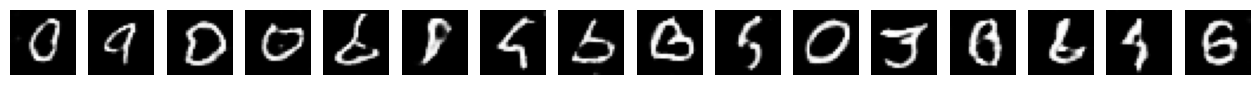

Epoch [7/25] Batch 0/469 	 D Loss: 7.6710 G Loss: 0.1891
Epoch [7/25] Batch 100/469 	 D Loss: 0.7489 G Loss: 1.0773
Epoch [7/25] Batch 200/469 	 D Loss: 1.0368 G Loss: 0.8455
Epoch [7/25] Batch 300/469 	 D Loss: 0.5927 G Loss: 1.9100
Epoch [7/25] Batch 400/469 	 D Loss: 0.7834 G Loss: 1.0528


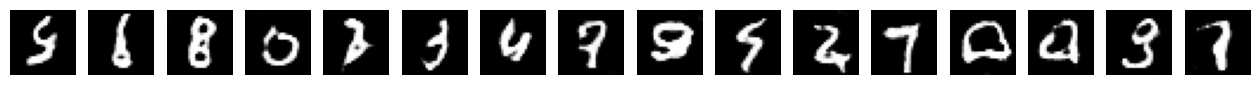

Epoch [8/25] Batch 0/469 	 D Loss: 1.9992 G Loss: 0.7828
Epoch [8/25] Batch 100/469 	 D Loss: 0.7792 G Loss: 1.0766
Epoch [8/25] Batch 200/469 	 D Loss: 0.6542 G Loss: 1.1003
Epoch [8/25] Batch 300/469 	 D Loss: 0.6178 G Loss: 1.3332
Epoch [8/25] Batch 400/469 	 D Loss: 0.5457 G Loss: 2.3153


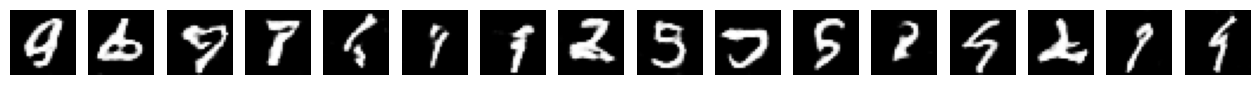

Epoch [9/25] Batch 0/469 	 D Loss: 0.7674 G Loss: 1.6018
Epoch [9/25] Batch 100/469 	 D Loss: 0.7346 G Loss: 2.2156
Epoch [9/25] Batch 200/469 	 D Loss: 0.8740 G Loss: 0.5838
Epoch [9/25] Batch 300/469 	 D Loss: 0.5218 G Loss: 1.8915
Epoch [9/25] Batch 400/469 	 D Loss: 0.6367 G Loss: 2.3490


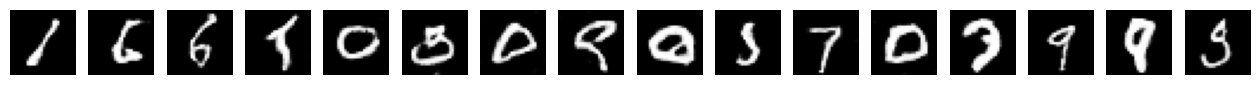

Epoch [10/25] Batch 0/469 	 D Loss: 0.4808 G Loss: 2.2107
Epoch [10/25] Batch 100/469 	 D Loss: 0.5987 G Loss: 1.6997
Epoch [10/25] Batch 200/469 	 D Loss: 0.5396 G Loss: 1.8247
Epoch [10/25] Batch 300/469 	 D Loss: 1.1946 G Loss: 3.7015
Epoch [10/25] Batch 400/469 	 D Loss: 0.7358 G Loss: 1.5755


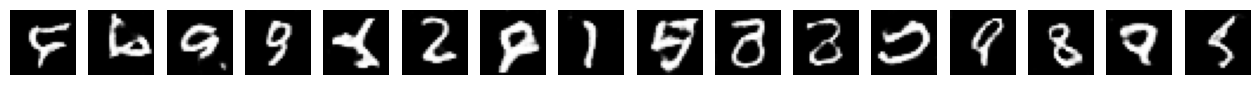

Epoch [11/25] Batch 0/469 	 D Loss: 0.5074 G Loss: 1.7061
Epoch [11/25] Batch 100/469 	 D Loss: 0.6224 G Loss: 1.3154
Epoch [11/25] Batch 200/469 	 D Loss: 0.6260 G Loss: 2.1946
Epoch [11/25] Batch 300/469 	 D Loss: 0.5789 G Loss: 2.1834
Epoch [11/25] Batch 400/469 	 D Loss: 0.8881 G Loss: 3.6051


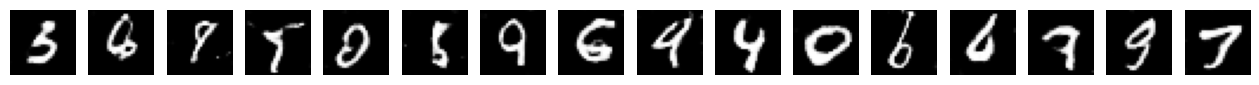

Epoch [12/25] Batch 0/469 	 D Loss: 0.5063 G Loss: 2.5124
Epoch [12/25] Batch 100/469 	 D Loss: 0.5841 G Loss: 2.5257
Epoch [12/25] Batch 200/469 	 D Loss: 0.8900 G Loss: 1.2128
Epoch [12/25] Batch 300/469 	 D Loss: 0.7030 G Loss: 2.6421
Epoch [12/25] Batch 400/469 	 D Loss: 0.5346 G Loss: 1.5061


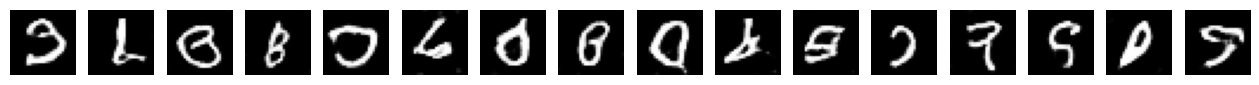

Epoch [13/25] Batch 0/469 	 D Loss: 0.6292 G Loss: 1.1751
Epoch [13/25] Batch 100/469 	 D Loss: 0.5522 G Loss: 1.5719
Epoch [13/25] Batch 200/469 	 D Loss: 0.6333 G Loss: 1.8583
Epoch [13/25] Batch 300/469 	 D Loss: 0.6645 G Loss: 1.2579
Epoch [13/25] Batch 400/469 	 D Loss: 0.5470 G Loss: 1.3434


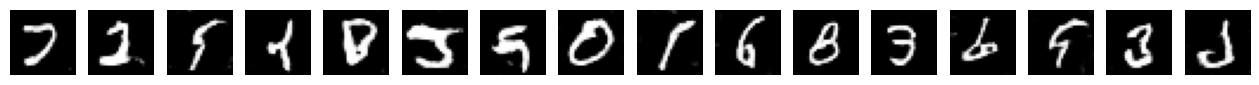

Epoch [14/25] Batch 0/469 	 D Loss: 0.5947 G Loss: 2.0892
Epoch [14/25] Batch 100/469 	 D Loss: 0.4034 G Loss: 1.5668
Epoch [14/25] Batch 200/469 	 D Loss: 0.6083 G Loss: 1.6318
Epoch [14/25] Batch 300/469 	 D Loss: 0.4973 G Loss: 2.0434
Epoch [14/25] Batch 400/469 	 D Loss: 0.8113 G Loss: 0.8535


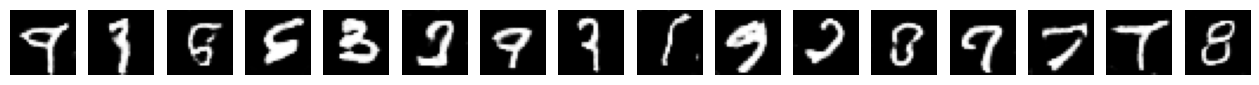

Epoch [15/25] Batch 0/469 	 D Loss: 0.6549 G Loss: 1.5717
Epoch [15/25] Batch 100/469 	 D Loss: 0.6660 G Loss: 2.3211
Epoch [15/25] Batch 200/469 	 D Loss: 0.5933 G Loss: 1.7348
Epoch [15/25] Batch 300/469 	 D Loss: 0.4986 G Loss: 2.5767
Epoch [15/25] Batch 400/469 	 D Loss: 0.7062 G Loss: 0.9131


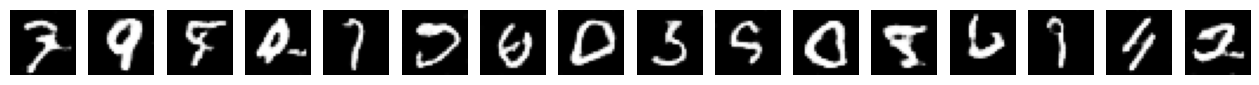

Epoch [16/25] Batch 0/469 	 D Loss: 0.7407 G Loss: 1.3978
Epoch [16/25] Batch 100/469 	 D Loss: 0.5289 G Loss: 1.9743
Epoch [16/25] Batch 200/469 	 D Loss: 0.6189 G Loss: 1.8404
Epoch [16/25] Batch 300/469 	 D Loss: 0.5899 G Loss: 1.3947
Epoch [16/25] Batch 400/469 	 D Loss: 0.7014 G Loss: 3.2061


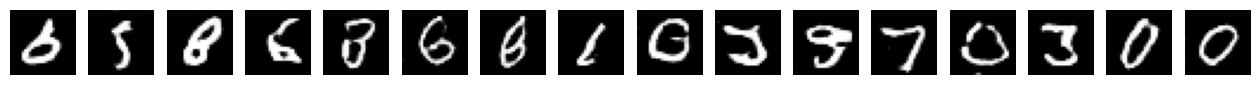

Epoch [17/25] Batch 0/469 	 D Loss: 0.7011 G Loss: 1.1674
Epoch [17/25] Batch 100/469 	 D Loss: 0.4698 G Loss: 1.7992
Epoch [17/25] Batch 200/469 	 D Loss: 0.4829 G Loss: 2.1178
Epoch [17/25] Batch 300/469 	 D Loss: 0.6290 G Loss: 2.8179
Epoch [17/25] Batch 400/469 	 D Loss: 0.5232 G Loss: 1.6509


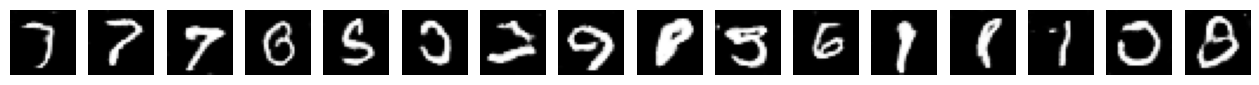

Epoch [18/25] Batch 0/469 	 D Loss: 0.5429 G Loss: 1.7552
Epoch [18/25] Batch 100/469 	 D Loss: 0.5413 G Loss: 1.3255
Epoch [18/25] Batch 200/469 	 D Loss: 0.5295 G Loss: 1.1276
Epoch [18/25] Batch 300/469 	 D Loss: 0.4556 G Loss: 1.9585
Epoch [18/25] Batch 400/469 	 D Loss: 0.5243 G Loss: 2.1223


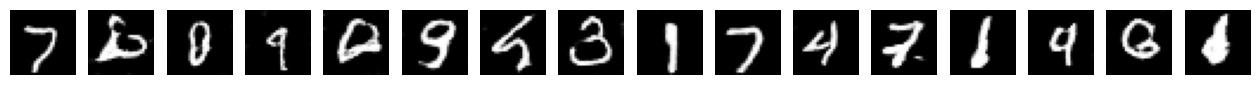

Epoch [19/25] Batch 0/469 	 D Loss: 0.4842 G Loss: 2.4248
Epoch [19/25] Batch 100/469 	 D Loss: 0.6013 G Loss: 1.4548
Epoch [19/25] Batch 200/469 	 D Loss: 0.5787 G Loss: 2.7814
Epoch [19/25] Batch 300/469 	 D Loss: 0.6716 G Loss: 1.1813
Epoch [19/25] Batch 400/469 	 D Loss: 1.1874 G Loss: 1.1880


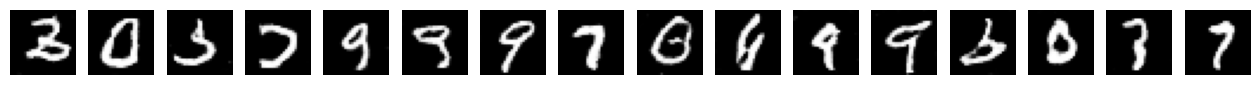

Epoch [20/25] Batch 0/469 	 D Loss: 1.1748 G Loss: 1.3678
Epoch [20/25] Batch 100/469 	 D Loss: 0.4392 G Loss: 3.5768
Epoch [20/25] Batch 200/469 	 D Loss: 0.6107 G Loss: 2.3871
Epoch [20/25] Batch 300/469 	 D Loss: 0.6228 G Loss: 2.0055
Epoch [20/25] Batch 400/469 	 D Loss: 0.3998 G Loss: 2.3034


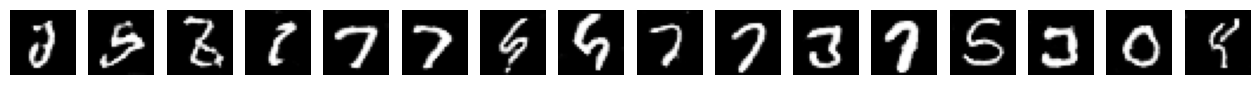

Epoch [21/25] Batch 0/469 	 D Loss: 0.4334 G Loss: 2.7434
Epoch [21/25] Batch 100/469 	 D Loss: 0.6784 G Loss: 2.4084
Epoch [21/25] Batch 200/469 	 D Loss: 0.6090 G Loss: 3.5954
Epoch [21/25] Batch 300/469 	 D Loss: 0.5224 G Loss: 2.5149
Epoch [21/25] Batch 400/469 	 D Loss: 0.4252 G Loss: 1.4869


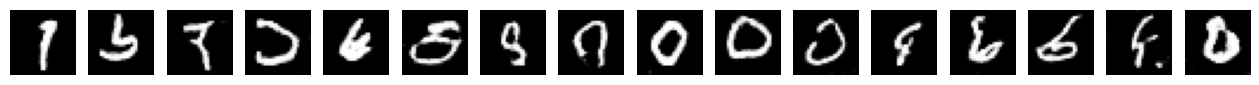

Epoch [22/25] Batch 0/469 	 D Loss: 0.4968 G Loss: 1.8978
Epoch [22/25] Batch 100/469 	 D Loss: 0.4908 G Loss: 2.6869
Epoch [22/25] Batch 200/469 	 D Loss: 0.7131 G Loss: 3.1688
Epoch [22/25] Batch 300/469 	 D Loss: 0.5213 G Loss: 3.6272
Epoch [22/25] Batch 400/469 	 D Loss: 0.5117 G Loss: 2.3422


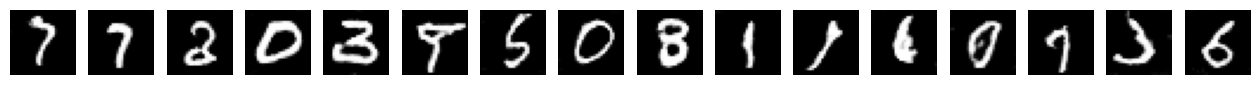

Epoch [23/25] Batch 0/469 	 D Loss: 0.4791 G Loss: 2.5964
Epoch [23/25] Batch 100/469 	 D Loss: 0.7190 G Loss: 3.0571
Epoch [23/25] Batch 200/469 	 D Loss: 0.5298 G Loss: 2.7920
Epoch [23/25] Batch 300/469 	 D Loss: 0.5010 G Loss: 2.3466
Epoch [23/25] Batch 400/469 	 D Loss: 0.6851 G Loss: 1.0817


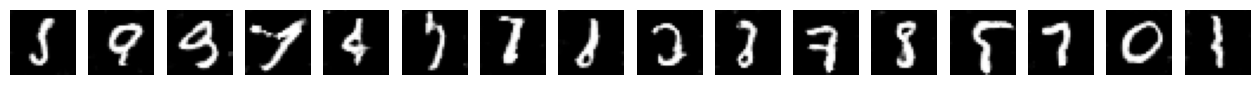

Epoch [24/25] Batch 0/469 	 D Loss: 0.4172 G Loss: 2.1458
Epoch [24/25] Batch 100/469 	 D Loss: 0.6324 G Loss: 2.2587
Epoch [24/25] Batch 200/469 	 D Loss: 0.3954 G Loss: 2.1759
Epoch [24/25] Batch 300/469 	 D Loss: 0.5937 G Loss: 2.9701
Epoch [24/25] Batch 400/469 	 D Loss: 0.5257 G Loss: 1.2090


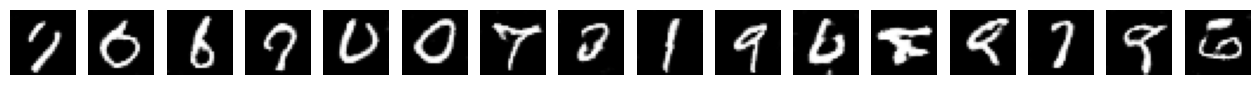

Training finished!


In [35]:
# Training loop
for epoch in range(epochs):
    for i, (real_imgs, _) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)
        
        # Train Discriminator
        optimizer_D.zero_grad()
        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)
        real_loss = criterion(discriminator(real_imgs), real_labels)
        
        z = torch.randn(batch_size, latent_dim, 1, 1, device=device)
        fake_imgs = generator(z)
        fake_loss = criterion(discriminator(fake_imgs.detach()), fake_labels)
        d_loss = real_loss + fake_loss
        d_loss.backward()
        optimizer_D.step()
        
        # Train Generator
        optimizer_G.zero_grad()
        g_loss = criterion(discriminator(fake_imgs), real_labels)
        g_loss.backward()
        optimizer_G.step()
        
        if i % 100 == 0:
            print(f"Epoch [{epoch}/{epochs}] Batch {i}/{len(dataloader)} \t D Loss: {d_loss.item():.4f} G Loss: {g_loss.item():.4f}")

    # Generate sample images at end of each epoch
    with torch.no_grad():
        z = torch.randn(16, latent_dim, 1, 1, device=device)
        samples = generator(z).cpu().detach()
        fig, axes = plt.subplots(1, 16, figsize=(16, 2))
        for img, ax in zip(samples, axes):
            ax.imshow(img.squeeze(), cmap='gray')
            ax.axis('off')
        plt.show()

print("Training finished!")

with discriminator step = 2

Epoch [0/25] Batch 0/469 	 D Loss: 1.0744 G Loss: 0.9486
Epoch [0/25] Batch 100/469 	 D Loss: 0.4342 G Loss: 1.6497
Epoch [0/25] Batch 200/469 	 D Loss: 0.7170 G Loss: 1.2307
Epoch [0/25] Batch 300/469 	 D Loss: 0.0680 G Loss: 3.5375
Epoch [0/25] Batch 400/469 	 D Loss: 0.0794 G Loss: 3.5795


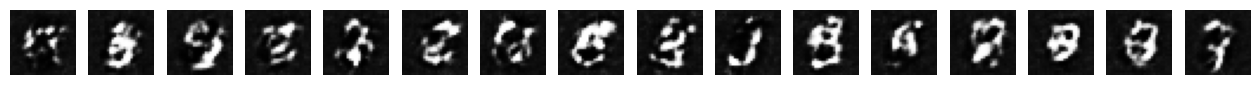

Epoch [1/25] Batch 0/469 	 D Loss: 0.0668 G Loss: 3.3831
Epoch [1/25] Batch 100/469 	 D Loss: 0.3541 G Loss: 1.6610
Epoch [1/25] Batch 200/469 	 D Loss: 0.1758 G Loss: 2.8373
Epoch [1/25] Batch 300/469 	 D Loss: 0.1736 G Loss: 3.0636
Epoch [1/25] Batch 400/469 	 D Loss: 0.1572 G Loss: 2.7136


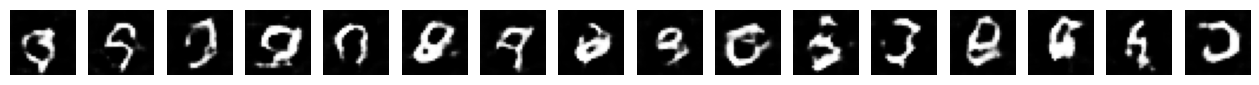

Epoch [2/25] Batch 0/469 	 D Loss: 0.1934 G Loss: 2.7901
Epoch [2/25] Batch 100/469 	 D Loss: 0.7713 G Loss: 1.1646
Epoch [2/25] Batch 200/469 	 D Loss: 0.1784 G Loss: 3.0913
Epoch [2/25] Batch 300/469 	 D Loss: 0.2933 G Loss: 3.7062
Epoch [2/25] Batch 400/469 	 D Loss: 0.4934 G Loss: 1.3437


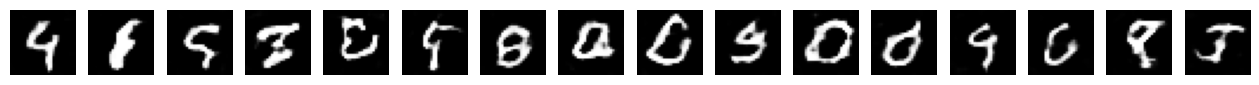

Epoch [3/25] Batch 0/469 	 D Loss: 0.2768 G Loss: 2.7399
Epoch [3/25] Batch 100/469 	 D Loss: 0.4027 G Loss: 1.2785
Epoch [3/25] Batch 200/469 	 D Loss: 0.2713 G Loss: 2.3181
Epoch [3/25] Batch 300/469 	 D Loss: 0.3999 G Loss: 2.8960
Epoch [3/25] Batch 400/469 	 D Loss: 0.4178 G Loss: 3.1447


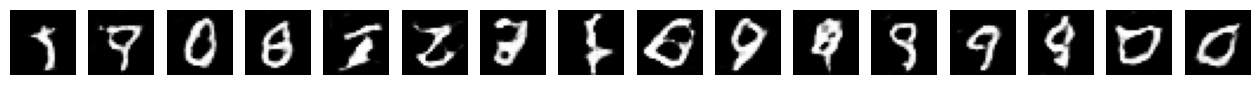

Epoch [4/25] Batch 0/469 	 D Loss: 0.5861 G Loss: 1.2845
Epoch [4/25] Batch 100/469 	 D Loss: 0.4007 G Loss: 1.7981
Epoch [4/25] Batch 200/469 	 D Loss: 0.5633 G Loss: 2.7737
Epoch [4/25] Batch 300/469 	 D Loss: 0.3390 G Loss: 2.1360
Epoch [4/25] Batch 400/469 	 D Loss: 0.3843 G Loss: 2.0243


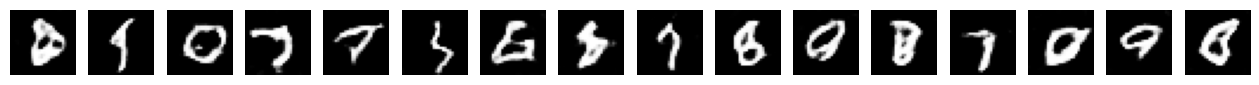

Epoch [5/25] Batch 0/469 	 D Loss: 0.4394 G Loss: 2.5535
Epoch [5/25] Batch 100/469 	 D Loss: 0.4317 G Loss: 1.9528
Epoch [5/25] Batch 200/469 	 D Loss: 0.3779 G Loss: 2.6168
Epoch [5/25] Batch 300/469 	 D Loss: 0.5789 G Loss: 2.0338
Epoch [5/25] Batch 400/469 	 D Loss: 0.3841 G Loss: 3.1602


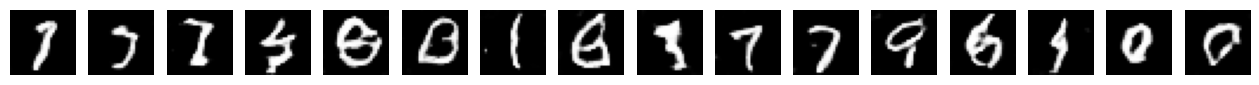

Epoch [6/25] Batch 0/469 	 D Loss: 0.3110 G Loss: 2.6845
Epoch [6/25] Batch 100/469 	 D Loss: 0.4780 G Loss: 1.7977
Epoch [6/25] Batch 200/469 	 D Loss: 0.6624 G Loss: 2.3823
Epoch [6/25] Batch 300/469 	 D Loss: 0.3325 G Loss: 2.1306
Epoch [6/25] Batch 400/469 	 D Loss: 0.3067 G Loss: 2.3645


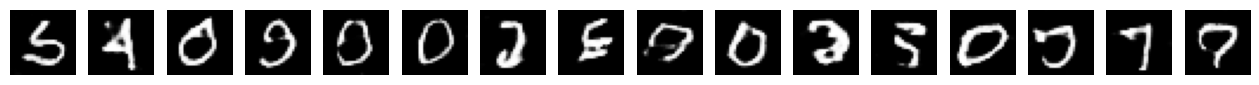

Epoch [7/25] Batch 0/469 	 D Loss: 0.3672 G Loss: 3.0749
Epoch [7/25] Batch 100/469 	 D Loss: 0.3067 G Loss: 2.7791
Epoch [7/25] Batch 200/469 	 D Loss: 0.5643 G Loss: 3.1100
Epoch [7/25] Batch 300/469 	 D Loss: 0.2351 G Loss: 2.4429
Epoch [7/25] Batch 400/469 	 D Loss: 0.6443 G Loss: 2.5224


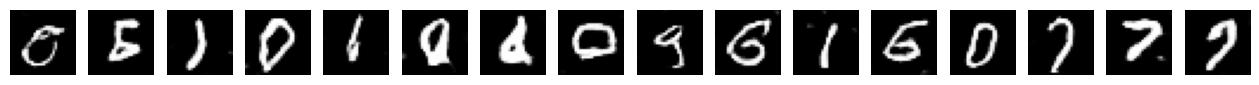

Epoch [8/25] Batch 0/469 	 D Loss: 0.3253 G Loss: 2.3056
Epoch [8/25] Batch 100/469 	 D Loss: 0.4891 G Loss: 2.6750
Epoch [8/25] Batch 200/469 	 D Loss: 0.3225 G Loss: 2.8046
Epoch [8/25] Batch 300/469 	 D Loss: 0.4153 G Loss: 2.3471
Epoch [8/25] Batch 400/469 	 D Loss: 0.4629 G Loss: 2.2931


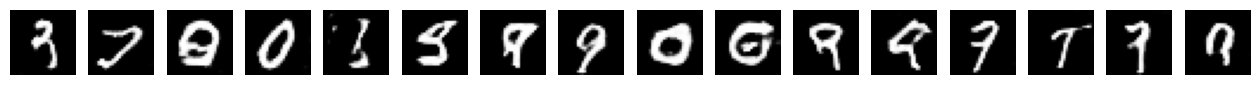

Epoch [9/25] Batch 0/469 	 D Loss: 0.3860 G Loss: 2.0527
Epoch [9/25] Batch 100/469 	 D Loss: 0.2908 G Loss: 2.6069
Epoch [9/25] Batch 200/469 	 D Loss: 0.3244 G Loss: 2.4423
Epoch [9/25] Batch 300/469 	 D Loss: 0.3617 G Loss: 2.0206
Epoch [9/25] Batch 400/469 	 D Loss: 0.2855 G Loss: 2.5569


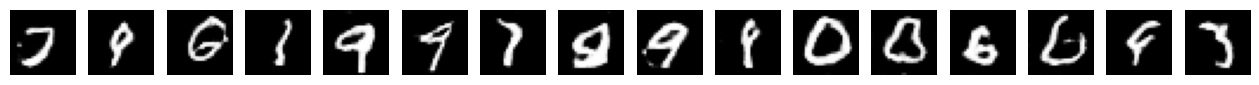

Epoch [10/25] Batch 0/469 	 D Loss: 0.4581 G Loss: 2.7536
Epoch [10/25] Batch 100/469 	 D Loss: 0.3449 G Loss: 3.9341
Epoch [10/25] Batch 200/469 	 D Loss: 0.5384 G Loss: 3.8508
Epoch [10/25] Batch 300/469 	 D Loss: 0.4930 G Loss: 3.5844
Epoch [10/25] Batch 400/469 	 D Loss: 0.3730 G Loss: 1.2767


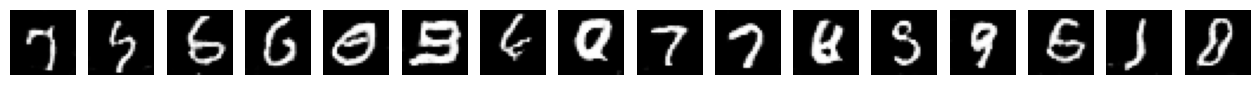

Epoch [11/25] Batch 0/469 	 D Loss: 0.4970 G Loss: 1.8484
Epoch [11/25] Batch 100/469 	 D Loss: 0.4122 G Loss: 1.8850
Epoch [11/25] Batch 200/469 	 D Loss: 0.2951 G Loss: 2.4327
Epoch [11/25] Batch 300/469 	 D Loss: 0.2877 G Loss: 2.3172
Epoch [11/25] Batch 400/469 	 D Loss: 0.3071 G Loss: 3.3427


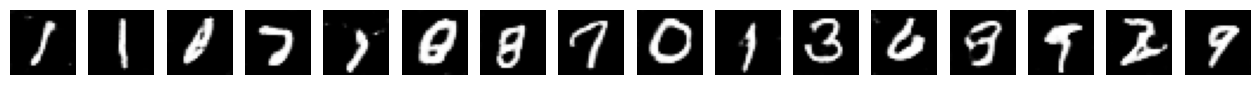

Epoch [12/25] Batch 0/469 	 D Loss: 0.2742 G Loss: 3.7512
Epoch [12/25] Batch 100/469 	 D Loss: 0.3697 G Loss: 3.5948
Epoch [12/25] Batch 200/469 	 D Loss: 1.3597 G Loss: 1.5849
Epoch [12/25] Batch 300/469 	 D Loss: 0.4235 G Loss: 2.5486
Epoch [12/25] Batch 400/469 	 D Loss: 0.2737 G Loss: 2.9711


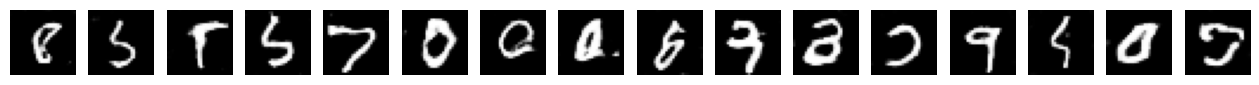

Epoch [13/25] Batch 0/469 	 D Loss: 0.5366 G Loss: 5.4765
Epoch [13/25] Batch 100/469 	 D Loss: 0.2344 G Loss: 3.1809
Epoch [13/25] Batch 200/469 	 D Loss: 0.2196 G Loss: 3.5192
Epoch [13/25] Batch 300/469 	 D Loss: 0.2582 G Loss: 3.5215
Epoch [13/25] Batch 400/469 	 D Loss: 0.2205 G Loss: 3.2409


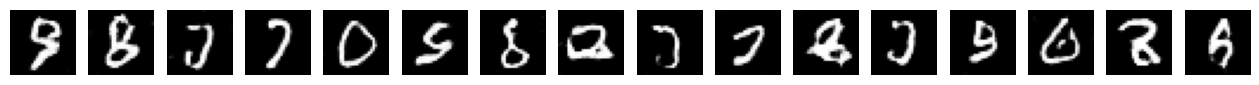

Epoch [14/25] Batch 0/469 	 D Loss: 0.6785 G Loss: 1.4757
Epoch [14/25] Batch 100/469 	 D Loss: 0.2544 G Loss: 3.9363
Epoch [14/25] Batch 200/469 	 D Loss: 0.3604 G Loss: 4.6192
Epoch [14/25] Batch 300/469 	 D Loss: 0.2696 G Loss: 2.3155
Epoch [14/25] Batch 400/469 	 D Loss: 0.3635 G Loss: 2.1146


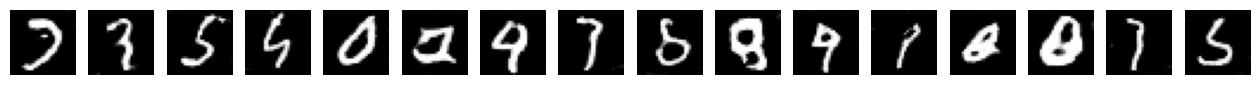

Epoch [15/25] Batch 0/469 	 D Loss: 0.2104 G Loss: 2.8828
Epoch [15/25] Batch 100/469 	 D Loss: 0.2595 G Loss: 2.6894
Epoch [15/25] Batch 200/469 	 D Loss: 0.2109 G Loss: 2.5795
Epoch [15/25] Batch 300/469 	 D Loss: 0.5138 G Loss: 3.1415
Epoch [15/25] Batch 400/469 	 D Loss: 0.3570 G Loss: 3.8367


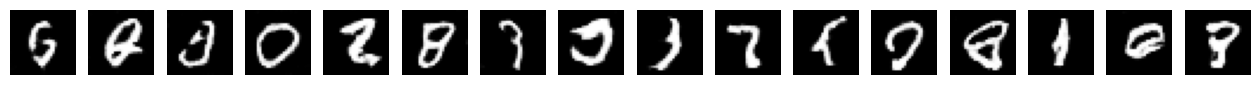

Epoch [16/25] Batch 0/469 	 D Loss: 1.0323 G Loss: 0.4090
Epoch [16/25] Batch 100/469 	 D Loss: 0.2975 G Loss: 3.9841
Epoch [16/25] Batch 200/469 	 D Loss: 0.2645 G Loss: 3.2372
Epoch [16/25] Batch 300/469 	 D Loss: 0.5753 G Loss: 6.2244
Epoch [16/25] Batch 400/469 	 D Loss: 0.2134 G Loss: 3.5998


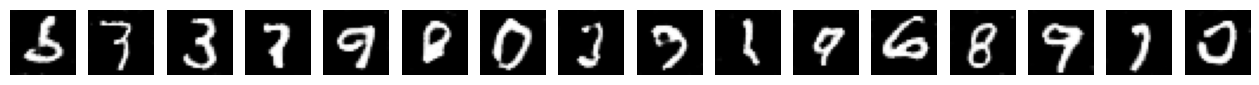

Epoch [17/25] Batch 0/469 	 D Loss: 0.2334 G Loss: 2.3491
Epoch [17/25] Batch 100/469 	 D Loss: 0.2551 G Loss: 3.5672
Epoch [17/25] Batch 200/469 	 D Loss: 0.2363 G Loss: 2.8601
Epoch [17/25] Batch 300/469 	 D Loss: 0.3064 G Loss: 3.8307
Epoch [17/25] Batch 400/469 	 D Loss: 0.1786 G Loss: 3.6503


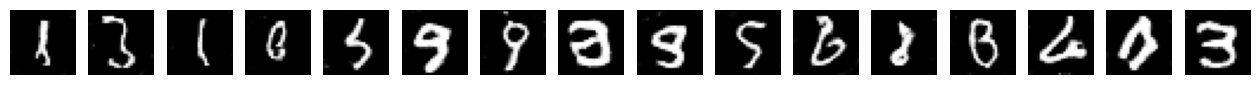

Epoch [18/25] Batch 0/469 	 D Loss: 0.4373 G Loss: 5.0512
Epoch [18/25] Batch 100/469 	 D Loss: 0.2640 G Loss: 2.3574
Epoch [18/25] Batch 200/469 	 D Loss: 0.3028 G Loss: 2.1408
Epoch [18/25] Batch 300/469 	 D Loss: 0.2170 G Loss: 2.6446
Epoch [18/25] Batch 400/469 	 D Loss: 0.2511 G Loss: 2.3615


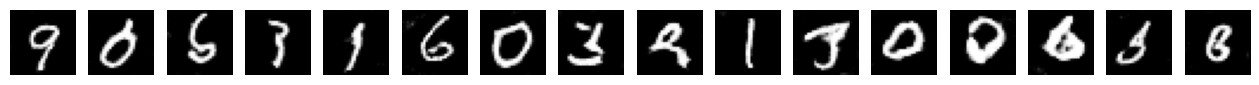

Epoch [19/25] Batch 0/469 	 D Loss: 0.3516 G Loss: 3.3817
Epoch [19/25] Batch 100/469 	 D Loss: 0.1616 G Loss: 3.5632
Epoch [19/25] Batch 200/469 	 D Loss: 0.2667 G Loss: 2.6454
Epoch [19/25] Batch 300/469 	 D Loss: 0.3220 G Loss: 2.2839
Epoch [19/25] Batch 400/469 	 D Loss: 1.0883 G Loss: 4.9363


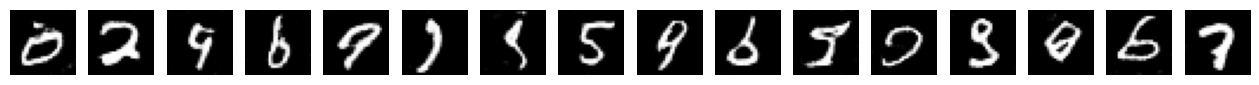

Epoch [20/25] Batch 0/469 	 D Loss: 0.1968 G Loss: 3.3338
Epoch [20/25] Batch 100/469 	 D Loss: 0.5782 G Loss: 5.7107
Epoch [20/25] Batch 200/469 	 D Loss: 0.3942 G Loss: 4.6745
Epoch [20/25] Batch 300/469 	 D Loss: 0.7272 G Loss: 4.9101
Epoch [20/25] Batch 400/469 	 D Loss: 0.3276 G Loss: 4.1641


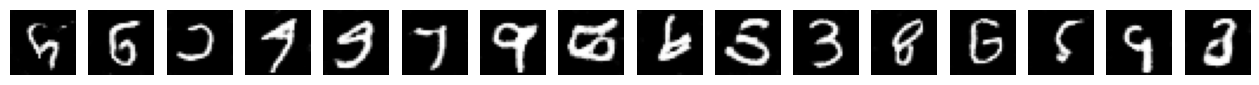

Epoch [21/25] Batch 0/469 	 D Loss: 0.2023 G Loss: 2.4465
Epoch [21/25] Batch 100/469 	 D Loss: 0.2983 G Loss: 2.3016
Epoch [21/25] Batch 200/469 	 D Loss: 0.3232 G Loss: 4.0871
Epoch [21/25] Batch 300/469 	 D Loss: 0.1851 G Loss: 3.5552
Epoch [21/25] Batch 400/469 	 D Loss: 0.3254 G Loss: 3.2359


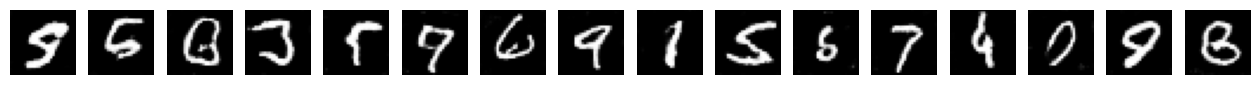

Epoch [22/25] Batch 0/469 	 D Loss: 0.2040 G Loss: 3.2254
Epoch [22/25] Batch 100/469 	 D Loss: 0.2958 G Loss: 4.4541
Epoch [22/25] Batch 200/469 	 D Loss: 0.2768 G Loss: 3.9825
Epoch [22/25] Batch 300/469 	 D Loss: 0.2259 G Loss: 2.3731
Epoch [22/25] Batch 400/469 	 D Loss: 0.2451 G Loss: 4.1121


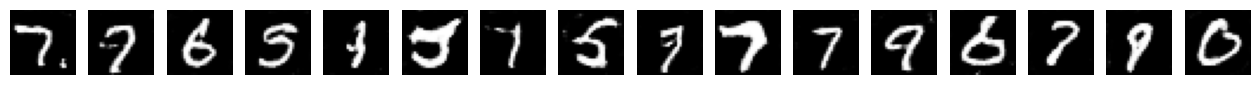

Epoch [23/25] Batch 0/469 	 D Loss: 0.2285 G Loss: 2.7609
Epoch [23/25] Batch 100/469 	 D Loss: 0.3664 G Loss: 1.6764
Epoch [23/25] Batch 200/469 	 D Loss: 0.2222 G Loss: 2.6504
Epoch [23/25] Batch 300/469 	 D Loss: 0.2099 G Loss: 2.6972
Epoch [23/25] Batch 400/469 	 D Loss: 0.2187 G Loss: 2.9636


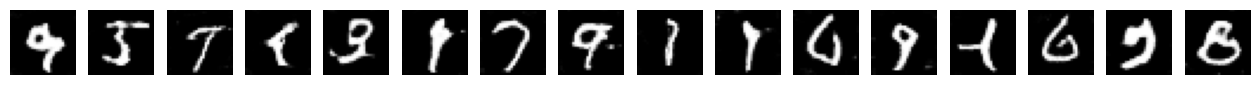

Epoch [24/25] Batch 0/469 	 D Loss: 0.2929 G Loss: 2.4138
Epoch [24/25] Batch 100/469 	 D Loss: 0.2567 G Loss: 2.5073
Epoch [24/25] Batch 200/469 	 D Loss: 0.2803 G Loss: 3.2054
Epoch [24/25] Batch 300/469 	 D Loss: 0.1964 G Loss: 3.2227
Epoch [24/25] Batch 400/469 	 D Loss: 0.1696 G Loss: 3.1363


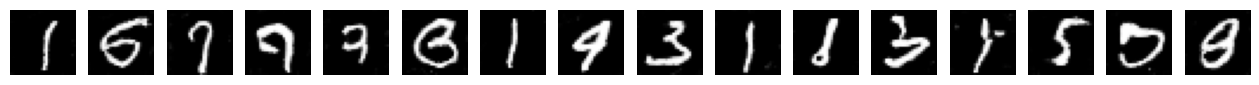

Training finished!


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Hyperparameters
latent_dim = 100
batch_size = 128
lr = 0.0002
beta1 = 0.5
epochs = 25
d_steps = 2  # Number of times discriminator is trained per generator step
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Generator class
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class Generator(nn.Module):
    def __init__(self, latent_dim):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, z):
        return self.model(z)

# Discriminator class
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )
    
    def forward(self, img):
        return self.model(img)

# Initialize models
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
generator.apply(weights_init)
discriminator.apply(weights_init)

# Optimizers and loss function
criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))

# Training loop
for epoch in range(epochs):
    for i, (real_imgs, _) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)
        
        for _ in range(d_steps):  # Train Discriminator multiple times per step
            optimizer_D.zero_grad()
            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)
            real_loss = criterion(discriminator(real_imgs), real_labels)
            
            z = torch.randn(batch_size, latent_dim, 1, 1, device=device)
            fake_imgs = generator(z)
            fake_loss = criterion(discriminator(fake_imgs.detach()), fake_labels)
            d_loss = real_loss + fake_loss
            d_loss.backward()
            optimizer_D.step()
        
        # Train Generator
        optimizer_G.zero_grad()
        g_loss = criterion(discriminator(fake_imgs), real_labels)
        g_loss.backward()
        optimizer_G.step()
        
        if i % 100 == 0:
            print(f"Epoch [{epoch}/{epochs}] Batch {i}/{len(dataloader)} \t D Loss: {d_loss.item():.4f} G Loss: {g_loss.item():.4f}")

    # Generate sample images at end of each epoch
    with torch.no_grad():
        z = torch.randn(16, latent_dim, 1, 1, device=device)
        samples = generator(z).cpu().detach()
        fig, axes = plt.subplots(1, 16, figsize=(16, 2))
        for img, ax in zip(samples, axes):
            ax.imshow(img.squeeze(), cmap='gray')
            ax.axis('off')
        plt.show()

print("Training finished!")

In [46]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from torchvision.models import inception_v3
from scipy.linalg import sqrtm

def compute_inception_score(generator, latent_dim, device, num_samples=1000):
    inception_model = inception_v3(pretrained=True, transform_input=False).to(device)
    inception_model.fc = nn.Identity()
    inception_model.eval()
    
    transform_resize = transforms.Compose([
        transforms.Resize((299, 299)),
        transforms.Lambda(lambda x: x.repeat(1, 3, 1, 1)),
    ])
    
    all_preds = []
    with torch.no_grad():
        for _ in range(num_samples // 100):
            z = torch.randn(100, latent_dim, 1, 1, device=device)
            samples = generator(z)
            samples = transform_resize(samples)  # Resize to 299x299 and convert to 3 channels
            preds = inception_model(samples).softmax(dim=-1).cpu().numpy()
            all_preds.append(preds)
    
    all_preds = np.concatenate(all_preds, axis=0)
    kl_div = all_preds * (np.log(all_preds) - np.log(np.mean(all_preds, axis=0, keepdims=True)))
    inception_score = np.exp(np.mean(np.sum(kl_div, axis=1)))
    return inception_score


# Hyperparameters
latent_dim = 100
batch_size = 128
lr = 0.0002
beta1 = 0.5
epochs = 50
d_steps = 2  # Number of times discriminator is trained per generator step
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data loading
transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(1, 3, 1, 1)),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Generator class
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class Generator(nn.Module):
    def __init__(self, latent_dim):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, z):
        return self.model(z)

# Discriminator class
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )
    
    def forward(self, img):
        return self.model(img)

# Initialize models
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)
generator.apply(weights_init)
discriminator.apply(weights_init)

# Optimizers and loss function
criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))

# Evaluate model
inception_score = compute_inception_score(generator, latent_dim, device)
print(f"Inception Score: {inception_score:.4f}")



Inception Score: 1.0358


In [51]:
import torch
import torchvision.transforms as transforms
from scipy.linalg import sqrtm
import numpy as np
import torch.nn as nn
from torchvision.models import inception_v3

def compute_fid(generator, real_dataloader, latent_dim, device, num_samples=1000):
    inception_model = inception_v3(pretrained=True, transform_input=False).to(device)
    inception_model.fc = nn.Identity()
    inception_model.eval()

    transform_resize = transforms.Resize((299, 299))

    def resize_batch(images):
        """ Resize a batch of images while converting grayscale (1-channel) to RGB (3-channel). """
        if images.shape[1] == 1:  # Grayscale images
            images = images.repeat(1, 3, 1, 1)  # Expand to 3 channels
        return torch.nn.functional.interpolate(images, size=(299, 299), mode="bilinear", align_corners=False)

    real_feats, fake_feats = [], []
    
    with torch.no_grad():
        for real_imgs, _ in real_dataloader:
            real_imgs = real_imgs.to(device)
            real_imgs = resize_batch(real_imgs)
            real_feats.append(inception_model(real_imgs).cpu().numpy())
            
        for _ in range(num_samples // 100):
            z = torch.randn(100, latent_dim, 1, 1, device=device)
            fake_imgs = generator(z)
            fake_imgs = resize_batch(fake_imgs)
            fake_feats.append(inception_model(fake_imgs).cpu().numpy())

    real_feats = np.concatenate(real_feats, axis=0)
    fake_feats = np.concatenate(fake_feats, axis=0)
    
    mu_real, sigma_real = real_feats.mean(axis=0), np.cov(real_feats, rowvar=False)
    mu_fake, sigma_fake = fake_feats.mean(axis=0), np.cov(fake_feats, rowvar=False)
    
    sigma_real += np.eye(sigma_real.shape[0]) * 1e-6
    sigma_fake += np.eye(sigma_fake.shape[0]) * 1e-6
    
    diff = mu_real - mu_fake
    covmean, _ = sqrtm(sigma_real @ sigma_fake, disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff.dot(diff) + np.trace(sigma_real + sigma_fake - 2 * covmean)
    return fid

fid_score = compute_fid(generator, dataloader, latent_dim, device)
print(f"FID Score: {fid_score:.4f}")


FID Score: 235.5906


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define Generator (Without BatchNorm to Induce Mode Collapse)
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, z):
        return self.model(z)

# Define Discriminator (Unchanged)
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )
    
    def forward(self, img):
        return self.model(img)

# Hyperparameters
latent_dim = 100
batch_size = 32  # Small batch size for poor gradient updates
lr = 0.0002
epochs = 10
d_steps = 5  # Discriminator is trained 5 times per generator update
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data Loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Initialize models
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

# Optimizers and loss function
criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=lr)
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr)

# Fixed latent vector (induces mode collapse)
fixed_noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)

# Training Loop (Inducing Mode Collapse)
for epoch in range(epochs):
    for real_imgs, _ in dataloader:
        real_imgs = real_imgs.to(device)
        
        # Train Discriminator more frequently
        for _ in range(d_steps):
            z = torch.randn(batch_size, latent_dim, 1, 1, device=device)
            fake_imgs = generator(z).detach()
            
            real_labels = torch.ones(batch_size, 1, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            real_loss = criterion(discriminator(real_imgs), real_labels)
            fake_loss = criterion(discriminator(fake_imgs), fake_labels)
            d_loss = real_loss + fake_loss
            
            optimizer_D.zero_grad()
            d_loss.backward()
            optimizer_D.step()

        # Train Generator with fixed noise (induces mode collapse)
        fake_imgs = generator(fixed_noise)
        loss_g = criterion(discriminator(fake_imgs), real_labels)

        optimizer_G.zero_grad()
        loss_g.backward()
        optimizer_G.step()

    print(f"Epoch {epoch+1}/{epochs} - D Loss: {d_loss.item():.4f}, G Loss: {loss_g.item():.4f}")

Epoch 1/10 - D Loss: 0.0008, G Loss: 0.9133
Epoch 2/10 - D Loss: 0.0000, G Loss: 0.3582
Epoch 3/10 - D Loss: 0.0012, G Loss: 0.5036
Epoch 4/10 - D Loss: 0.0000, G Loss: 0.0630
Epoch 5/10 - D Loss: 0.0000, G Loss: 0.0372
Epoch 6/10 - D Loss: 0.0084, G Loss: 0.5595
Epoch 7/10 - D Loss: 0.0001, G Loss: 0.0025
Epoch 8/10 - D Loss: 0.0000, G Loss: 0.0017
Epoch 9/10 - D Loss: 0.0000, G Loss: 0.0008
Epoch 10/10 - D Loss: 0.0000, G Loss: 0.0058


In [7]:
def compute_pairwise_distance(generator, latent_dim, device, num_samples=1000):
    features = []
    with torch.no_grad():
        for _ in range(num_samples // batch_size):
            z = torch.randn(batch_size, latent_dim, 1, 1, device=device)
            fake_imgs = generator(z).cpu().numpy().reshape(batch_size, -1)  # Flatten images
            features.append(fake_imgs)

    features = np.concatenate(features, axis=0)
    distances = np.linalg.norm(features[:, None, :] - features[None, :, :], axis=-1)
    return np.mean(distances)

# Example usage:
diversity_score = compute_pairwise_distance(generator, latent_dim, device)
print(f"Diversity Score: {diversity_score}")

Diversity Score: 19.0024356842041


# 3. Zero-short Learning

In [29]:
import torch
import clip
from torchvision import datasets, transforms
from PIL import Image
import numpy as np

# Load CLIP model
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

# Load MNIST test dataset
transform = transforms.Compose([
    transforms.Grayscale(3),  # Convert single-channel MNIST to 3-channel
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_dataset = datasets.MNIST(root="./data", train=False, transform=transform, download=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define text descriptions for MNIST digits
class_labels = [f"the handwritten digit {i}" for i in range(10)]
tokenized_texts = clip.tokenize(class_labels).to(device)

# Compute text embeddings
with torch.no_grad():
    text_features = model.encode_text(tokenized_texts)
    text_features /= text_features.norm(dim=-1, keepdim=True)

In [30]:
# Evaluate on MNIST test set
correct = 0
total = 0
image_embeddings = []
true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        image_features = model.encode_image(images)
        image_features /= image_features.norm(dim=-1, keepdim=True)
        
        # Compute similarity scores
        similarities = (image_features @ text_features.T)  # Cosine similarity
        predictions = similarities.argmax(dim=1).cpu().numpy()
        
        correct += np.sum(predictions == labels.numpy())
        total += labels.size(0)
        
        image_embeddings.append(image_features.cpu().numpy())
        true_labels.extend(labels.numpy())

accuracy = correct / total
print(f"Zero-shot CLIP accuracy on MNIST: {accuracy:.4f}")

Zero-shot CLIP accuracy on MNIST: 0.2665


The accuracy of the zero-shot CLIP model on MNIST is calculated by comparing the cosine similarity between image embeddings and text embeddings of class labels (e.g., "the handwritten digit zero").
If the accuracy is low, it's because CLIP's representations for "handwritten digits" are not optimal. If the accuracy is reasonable (~50%+), it indicates that CLIP captures some meaningful features for distinguishing digits.

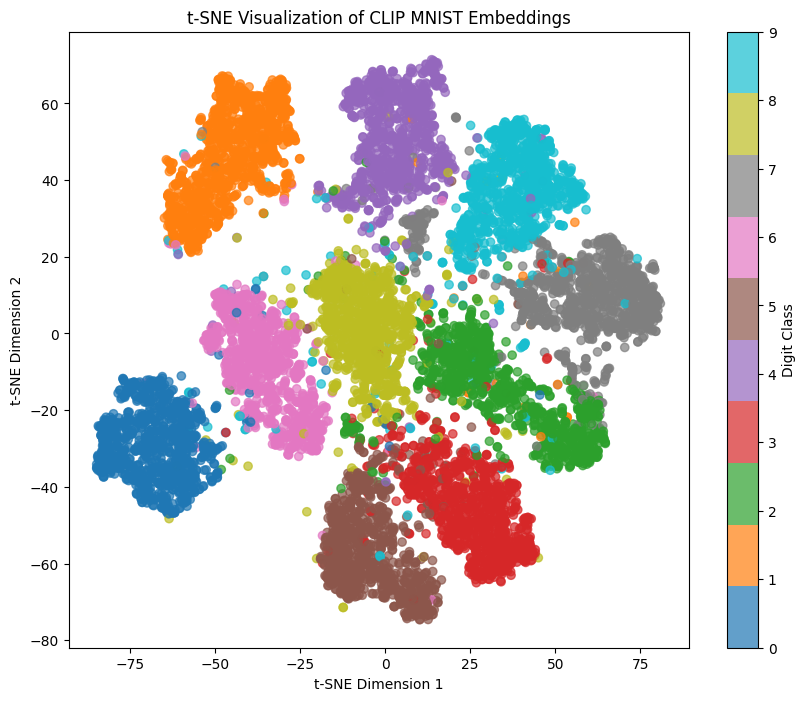

In [31]:
from sklearn.manifold import TSNE
# Convert embeddings to 2D using t-SNE
image_embeddings = np.vstack(image_embeddings)
tsne = TSNE(n_components=2, random_state=42)
tsne_embeddings = tsne.fit_transform(image_embeddings)

# Plot t-SNE results
plt.figure(figsize=(10, 8))
scatter = plt.scatter(tsne_embeddings[:, 0], tsne_embeddings[:, 1], c=true_labels, cmap='tab10', alpha=0.7)
plt.colorbar(scatter, label="Digit Class")
plt.title("t-SNE Visualization of CLIP MNIST Embeddings")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()